In [136]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.preprocessing import OneHotEncoder # 원핫 인코딩
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [137]:
# 데이터 가져오기
# manhattan.csv
# LinearRegression() 을 사용해서 랜탈비를 예측하시오
df = pd.read_csv('data/manhattan.csv',index_col='rental_id')
# 데이터 전처리
data = df.drop(columns=df.columns[[0,15,16]]).values 
data2 = df[['neighborhood','borough']].values
label = df['rent'].values
# len(df.columns)
df['neighborhood'].unique() # 32개
df['borough'].unique() # 1개

<StringArray>
['Manhattan']
Length: 1, dtype: str

In [138]:
neigbor = df['neighborhood'].to_numpy().reshape(-1,1)
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(neigbor)
result

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(3539, 31))

In [139]:
total_data = np.concatenate((data,result),axis=1)
total_data

array([[0.00e+00, 1.00e+00, 4.80e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [2.00e+00, 2.00e+00, 2.00e+03, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 9.16e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       ...,
       [0.00e+00, 1.00e+00, 2.50e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 6.51e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 8.16e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00]],
      shape=(3539, 45))

In [133]:
# 데이터 분리1
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)
train_data[0]

array([  1.,   1., 592.,   1.,   7., 116.,   1.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.])

In [140]:
# 데이터 분리2
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=42)
train_data[0]

array([  1.,   1., 592.,   1.,   7., 116.,   1.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.])

In [141]:
poly = PolynomialFeatures(degree=2,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)


In [135]:
# 데이터 학습1 
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측1
predict = lr.predict(test_poly)

# 정확도1
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2

(0.8125765930112304, 0.7876090606961061)

In [142]:
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
train_scaled

array([[-0.37344357, -0.61111056, -0.73111508, ..., -0.01941473,
         0.        , -0.1399742 ],
       [ 0.66220872, -0.61111056, -0.291808  , ..., -0.01941473,
         0.        , -0.1399742 ],
       [ 0.66220872,  1.05065934,  0.46279123, ..., -0.01941473,
         0.        , -0.1399742 ],
       ...,
       [ 2.73351331,  2.71242923,  2.22842733, ..., -0.01941473,
         0.        , -0.1399742 ],
       [ 0.66220872, -0.61111056, -0.50410472, ..., -0.01941473,
         0.        , -0.1399742 ],
       [-1.40909587, -0.61111056, -0.93080011, ..., -0.01941473,
         0.        , -0.1399742 ]], shape=(2654, 1080))

In [143]:
alpha_list = [0.001,0.01,0.1,1,10,100]

s_list = []
s_list1 = []

for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    s_list.append(score)
    s_list1.append(score2)
s_list,s_list1

([0.8997428353686099,
  0.8997427813426514,
  0.8997386905105822,
  0.899641224838694,
  0.8987565861280757,
  0.8907100532475399],
 [0.794061155402682,
  0.7941394144992704,
  0.7947832673882685,
  0.7973433728280125,
  0.8039141469689879,
  0.8130459207736604])

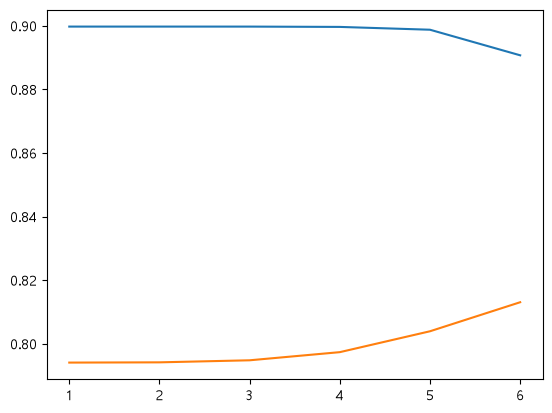

In [144]:
x = [1,2,3,4,5,6]
plt.plot(x,s_list)
plt.plot(x,s_list1)


In [145]:
# 데이터 학습2
ridge = Ridge(alpha=100)
ridge.fit(train_scaled,train_label)

# 데이터 예측2
predict = ridge.predict(test_scaled)

# 정확도2
scor = ridge.score(train_scaled,train_label)
scor2 = ridge.score(test_scaled,test_label)
scor,scor2

(0.8907100532475399, 0.8130459207736604)